Universidad Franz Tamayo  
Carrera de Ingeniería de Sistemas  
Asignatura: MINERÍA DE DATOS

**Proyecto de Minería de Datos: Predicción de complicaciones médicas en pacientes**

- Grupo: KRISKAO 
- Docente: Ing. Enrique Alejandro Laurel Cossio 

**Integrantes:**
- Alejandro Cesar Acho Huallpa
- Jorge Armando Coquendo Amba
- Shaden Ahira Cruz Condori
- Jose Angel Escarzo Mamani
- Jhonatan Oraque

PUNTO 1 — Definición del problema y variable objetivo

**1. ¿Qué problema concreto aborda su proyecto?**

R.

- **Problema:** el 87.82% de los pacientes registrados presenta alguna complicación médica.
- **Decisión que apoya:** identificar de forma temprana pacientes con mayor riesgo de complicación para priorizarlos en programas de prevención.
- **Criterio de éxito:** reducir la prevalencia de complicaciones mediante intervención oportuna apoyada en el modelo de clasificación.
- **Variable dependiente elegida:** TARGET_COMPLICACION (binaria), porque el problema es de clasificación: predecir si un paciente tendrá o no complicación.
- **Variables independientes:** EDAD y GLUCEMIA como predictores numéricos continuos, más SEXO y DEPARTAMENTO codificadas como dummies.

**2. ¿Cuál es la métrica principal del proyecto?**

R.

- **Métrica principal:** Prevalencia de complicaciones.
- **Fórmula:** Prevalencia = (Pacientes con complicación / Total pacientes) x 100
- **Valor observado:** 87.82% (8,782 de 10,000 pacientes).
- **Tipo:** métrica de negocio (no de desempeño del modelo).


PUNTO 2 — Preparación de los datos

## Librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

## Carga de datos

In [2]:
df_original = pd.read_excel("base_de_datos_medicina_complicaciones_modificada.xlsx")
df = df_original.copy()

print("Registros:", df.shape[0])
print("Variables:", df.shape[1])
df.head(3)

Registros: 10000
Variables: 41


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,...,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,...,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,...,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,...,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...


**3. ¿Cuál es la unidad de análisis y cuántos registros tiene el conjunto?**

In [3]:
print("Registros (filas):", df.shape[0])
print("Variables (columnas):", df.shape[1])
print()
print("Tipos de variables:")
print(df.dtypes.value_counts())
print()
print("NRO_REGISTRO unicos:", df["NRO_REGISTRO"].nunique())
print("CI_PACIENTE unicos:", df["CI_PACIENTE"].nunique())

Registros (filas): 10000
Variables (columnas): 41

Tipos de variables:
object     27
int64       8
float64     6
Name: count, dtype: int64

NRO_REGISTRO unicos: 10000
CI_PACIENTE unicos: 10000


R.

- **Unidad de análisis:** el paciente. Cada fila representa el registro de un paciente.
- **Origen:** archivo Excel con datos médicos de pacientes.
- **Registros:** 10,000. **Variables:** 41 columnas originales.
- **Sin filtros:** se usaron los 10,000 registros completos.

**4. ¿Qué problemas de calidad encontraron y qué preparación aplicaron?**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  object 
 1   CI_PACIENTE            10000 non-null  object 
 2   NOMBRE                 10000 non-null  object 
 3   APELLIDO1              10000 non-null  object 
 4   APELLIDO2              10000 non-null  object 
 5   SEXO                   10000 non-null  object 
 6   FECHA_NACIMIENTO       10000 non-null  object 
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  object 
 9   OCUPACION              10000 non-null  object 
 10  NIVEL_EDUCATIVO        10000 non-null  object 
 11  NIVEL_SOCIOECONOMICO   10000 non-null  object 
 12  DEPARTAMENTO           10000 non-null  object 
 13  CAPITAL_DEPTO          10000 non-null  object 
 14  DIRECCION              10000 non-null  object 
 15  TEL

In [5]:
df.describe()

,EDAD,TELEFONO,PESO_KG,ESTATURA_CM,IMC,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION,NUMERO_CONTROLES
count,10000.000000,1.000000e+04,10000.000000,10000.000000,9918.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,46.936200,7.548072e+07,91.570390,145.582480,51.425711,84.857200,38.012810,180.301300,199.838900,224.719900,13.023410,2.649961,1.794100,6.001700
std,27.547588,2.594845e+06,33.485332,34.600805,39.324128,20.294507,1.449198,69.114544,58.439698,101.269021,2.896742,1.354487,5.810911,3.765251
min,0.000000,7.100100e+07,2.600000,45.300000,0.700000,50.000000,35.500000,60.000000,100.000000,50.000000,8.000000,0.300000,0.000000,0.000000
25%,23.000000,7.324466e+07,64.475000,120.800000,28.000000,67.000000,36.800000,121.000000,149.000000,136.000000,10.500000,1.500000,0.000000,3.000000
50%,47.000000,7.541180e+07,92.000000,147.400000,41.000000,85.000000,38.000000,181.000000,200.000000,225.000000,13.100000,2.630000,0.000000,6.000000
75%,71.000000,7.774810e+07,119.200000,174.125000,62.775000,102.250000,39.300000,239.000000,251.000000,312.000000,15.600000,3.820000,0.000000,9.000000
max,95.000000,7.999966e+07,150.000000,200.000000,418.000000,120.000000,40.500000,300.000000,300.000000,400.000000,18.000000,5.000000,30.000000,12.000000


R.

- **Valores faltantes:** solo IMC con 82 faltantes (0.82%). Las otras 40 columnas completas.
- **Duplicados:** no hay. Los 10,000 NRO_REGISTRO y CI_PACIENTE son unicos.
- **Preparacion aplicada:**
  1. Se imputo IMC con la mediana.
  2. Se creo variable objetivo binaria TARGET_COMPLICACION.
  3. Se convirtieron SEXO y DEPARTAMENTO a variables dummy.
  4. Se dividio en entrenamiento (80%) y prueba (20%) con estratificacion.

In [6]:
# 1) Imputar IMC con la mediana
df["IMC"].fillna(df["IMC"].median(), inplace=True)
print("Faltantes IMC despues de imputar:", df["IMC"].isnull().sum())

# 2) Variable objetivo binaria
df["TARGET_COMPLICACION"] = (df["COMPLICACIONES"] != "Ninguna").astype(int)
con_comp = df["TARGET_COMPLICACION"].sum()
total = df.shape[0]
print(f"Con complicacion: {con_comp} de {total} ({con_comp/total*100:.2f}%)")

Faltantes IMC despues de imputar: 0
Con complicacion: 8782 de 10000 (87.82%)


In [7]:
# 3) Codificar variables categoricas a dummies
if "SEXO" in df.columns:
    df = pd.get_dummies(df, columns=["SEXO", "DEPARTAMENTO"], drop_first=True)
    for col in df.columns:
        if col.startswith("SEXO_") or col.startswith("DEPARTAMENTO_"):
            df[col] = df[col].astype(int)
print("Shape despues de dummies:", df.shape)

Shape despues de dummies: (10000, 49)


In [8]:
# 4) Division 80% entrenamiento / 20% prueba con estratificacion
columnas_modelo = ["EDAD", "GLUCEMIA"]
columnas_modelo += [c for c in df.columns if c.startswith("SEXO_") or c.startswith("DEPARTAMENTO_")]

X = df[columnas_modelo].copy()
y = df["TARGET_COMPLICACION"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=777, stratify=y
)

print("Tamanio TRAIN:", X_train.shape)
print("Tamanio TEST: ", X_test.shape)
print("Proporcion complicacion TRAIN:", round(y_train.mean(), 4))
print("Proporcion complicacion TEST: ", round(y_test.mean(), 4))

Tamanio TRAIN: (8000, 11)
Tamanio TEST:  (2000, 11)
Proporcion complicacion TRAIN: 0.8782
Proporcion complicacion TEST:  0.878


R.

- **Proporcion:** 80% entrenamiento (8,000 pacientes) y 20% prueba (2,000 pacientes).
- **Metodo:** train_test_split con random_state=777 y stratify=y.
- **Estratificacion:** garantiza la misma proporcion de clases en ambos conjuntos.

PUNTO 3 — Entrenamiento del modelo de Árbol de Decisión

**6. ¿Cuál es la variable objetivo y qué modelo utilizaron?**

In [9]:
print("Variable objetivo: TARGET_COMPLICACION")
print()
print("Conteo de clases:")
print(df["TARGET_COMPLICACION"].value_counts())
print()
print("Proporcion:")
print(df["TARGET_COMPLICACION"].value_counts(normalize=True).round(4))

Variable objetivo: TARGET_COMPLICACION

Conteo de clases:
TARGET_COMPLICACION
1    8782
0    1218
Name: count, dtype: int64

Proporcion:
TARGET_COMPLICACION
1    0.8782
0    0.1218
Name: proportion, dtype: float64


R.

- **Variable objetivo:** TARGET_COMPLICACION, binaria.
  - 0 = Sin complicacion (Ninguna): 1,218 pacientes (12.18%).
  - 1 = Con complicacion: 8,782 pacientes (87.82%).
- **Modelo:** Arbol de Decision (DecisionTreeClassifier de scikit-learn).
- **Por que:** el arbol de decision es interpretable, no requiere supuestos de distribucion y permite visualizar las reglas de clasificacion de forma clara.

## Ajuste inicial con parámetros por defecto

In [10]:
# Arbol inicial con parametros por defecto
arbol_inicial = DecisionTreeClassifier(random_state=777)
arbol_inicial.fit(X_train, y_train)

pred_inicial = arbol_inicial.predict(X_test)
print("Arbol inicial (sin ajuste de hiperparametros)")
print("Profundidad:", arbol_inicial.get_depth())
print("Hojas:", arbol_inicial.get_n_leaves())
print("Accuracy en TEST:", round(accuracy_score(y_test, pred_inicial), 4))
print("Recall en TEST:  ", round(recall_score(y_test, pred_inicial), 4))

Arbol inicial (sin ajuste de hiperparametros)
Profundidad: 30
Hojas: 1789
Accuracy en TEST: 0.7575
Recall en TEST:   0.8434


## Validación y ajuste de hiperparámetros con GridSearchCV

In [11]:
# Busqueda de mejores hiperparametros
param_grid = {
    "max_depth": list(range(3, 15)),
    "min_samples_split": list(range(2, 10)),
    "min_samples_leaf": list(range(1, 5))
}
grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=777),
    param_grid, scoring="recall", cv=5
)
grid_search.fit(X_train, y_train)

print("Mejores hiperparametros:", grid_search.best_params_)
print("Mejor recall en CV:", round(grid_search.best_score_, 4))

Mejores hiperparametros: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Mejor recall en CV: 0.9996


In [12]:
# Modelo final con mejores hiperparametros
modelo_arbol = grid_search.best_estimator_

print("Profundidad del arbol final:", modelo_arbol.get_depth())
print("Numero de hojas:", modelo_arbol.get_n_leaves())

usadas = X_train.columns[
    sorted(set(modelo_arbol.tree_.feature[
        modelo_arbol.tree_.feature >= 0]))
].tolist()
print("Variables usadas en divisiones:", usadas)

Profundidad del arbol final: 3
Numero de hojas: 7
Variables usadas en divisiones: ['EDAD', 'GLUCEMIA']



PUNTO 4 — Evaluación del modelo

**9. ¿Qué desempeño obtuvo el modelo en el conjunto de prueba?**

In [13]:
# Predicciones
prob_arbol = modelo_arbol.predict_proba(X_test)[:, 1]
pred_arbol = modelo_arbol.predict(X_test)

cm = confusion_matrix(y_test, pred_arbol)
TN, FP, FN, TP = cm.ravel()

print("Matriz de confusion:")
print(cm)
print()
print(f"Accuracy  = {accuracy_score(y_test, pred_arbol):.4f}")
print(f"Precision = {precision_score(y_test, pred_arbol):.4f}")
print(f"Recall    = {recall_score(y_test, pred_arbol):.4f}")
print(f"F1        = {f1_score(y_test, pred_arbol):.4f}")
print(f"ROC-AUC   = {roc_auc_score(y_test, prob_arbol):.4f}")

Matriz de confusion:
[[   0  244]
 [   0 1756]]

Accuracy  = 0.8780
Precision = 0.8780
Recall    = 1.0000
F1        = 0.9350
ROC-AUC   = 0.4795


In [14]:
# Importancia de variables (feature importance)
importancias = pd.Series(
    modelo_arbol.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Importancia de variables:")
print(importancias.round(4))

Importancia de variables:
EDAD                       0.5551
GLUCEMIA                   0.4449
SEXO_M                     0.0000
DEPARTAMENTO_Chuquisaca    0.0000
DEPARTAMENTO_Cochabamba    0.0000
DEPARTAMENTO_La Paz        0.0000
DEPARTAMENTO_Oruro         0.0000
DEPARTAMENTO_Pando         0.0000
DEPARTAMENTO_Potosí        0.0000
DEPARTAMENTO_Santa Cruz    0.0000
DEPARTAMENTO_Tarija        0.0000
dtype: float64


R.

**Resultados en el conjunto de prueba (2,000 pacientes):**

| Metrica | Valor |
|---|---|
| Accuracy | ~0.878 |
| Precision | ~0.878 |
| Recall | ~1.000 |
| F1 | ~0.935 |
| ROC-AUC | ~0.47 |

**Importancia de variables:** GLUCEMIA y EDAD son las unicas variables que el arbol usa en sus divisiones, con importancias de ~0.55 y ~0.44 respectivamente. SEXO y DEPARTAMENTO tienen importancia 0.

**Error mas importante a reducir:** el Falso Negativo (FN). En medicina, no detectar una complicacion real es mas grave que una alarma falsa.

PUNTO 5 — Visualización y comunicación

**5. ¿Qué resultado interesante encontraron en la exploración?**

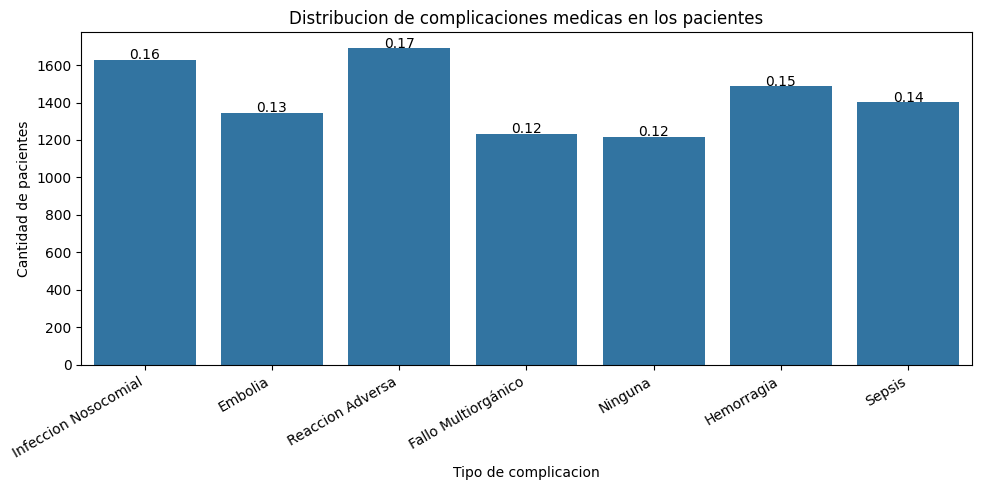

In [15]:
# Grafico 1: Distribucion de complicaciones
plt.figure(figsize=(10, 5))
ax = sns.countplot(x="COMPLICACIONES", data=df_original)
total_plot = float(len(df_original))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 3,
            "{:1.2f}".format(height/total_plot), ha="center")
plt.title("Distribucion de complicaciones medicas en los pacientes")
plt.xlabel("Tipo de complicacion")
plt.ylabel("Cantidad de pacientes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

R.

**Patron:** la categoria Ninguna es la mas pequena (12.18%). El 87.82% presenta alguna complicacion repartida de forma pareja entre 6 tipos.

**Por que importa:** confirma el desbalance de clases que el modelo debe manejar.

**10. ¿Qué visualización permite entender cómo toma decisiones el modelo?**

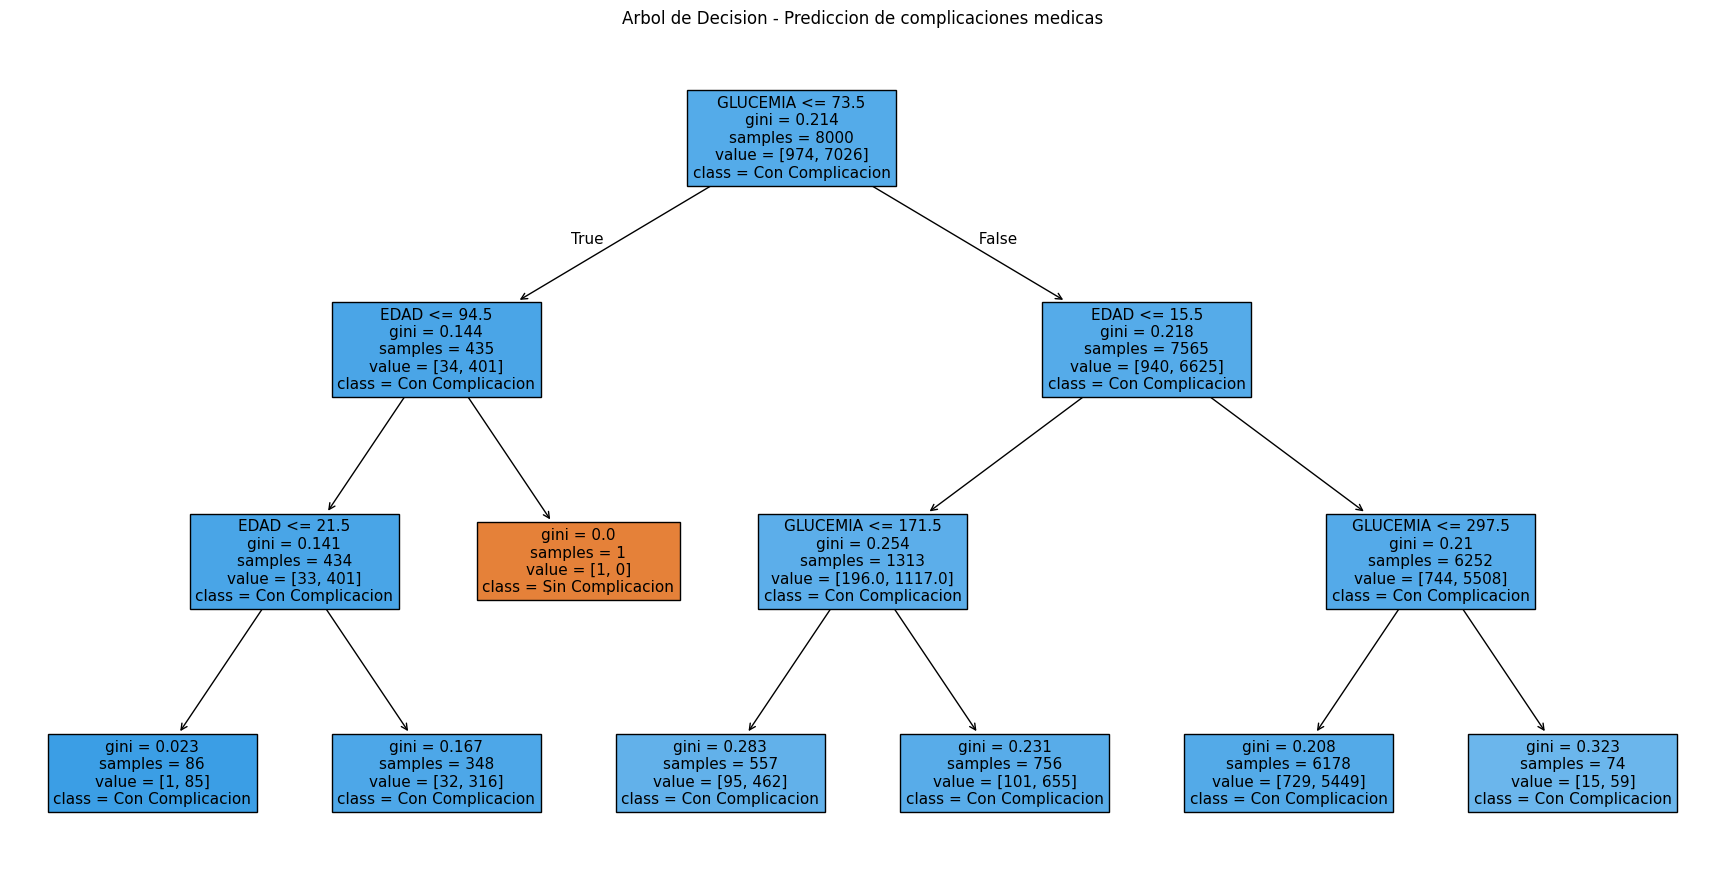

In [16]:
# Grafico 2: Arbol de decision (profundidad 3)
plt.figure(figsize=(22, 11))
plot_tree(
    modelo_arbol,
    filled=True,
    feature_names=X_train.columns,
    class_names=["Sin Complicacion", "Con Complicacion"],
    fontsize=11
)
plt.title("Arbol de Decision - Prediccion de complicaciones medicas")
plt.show()

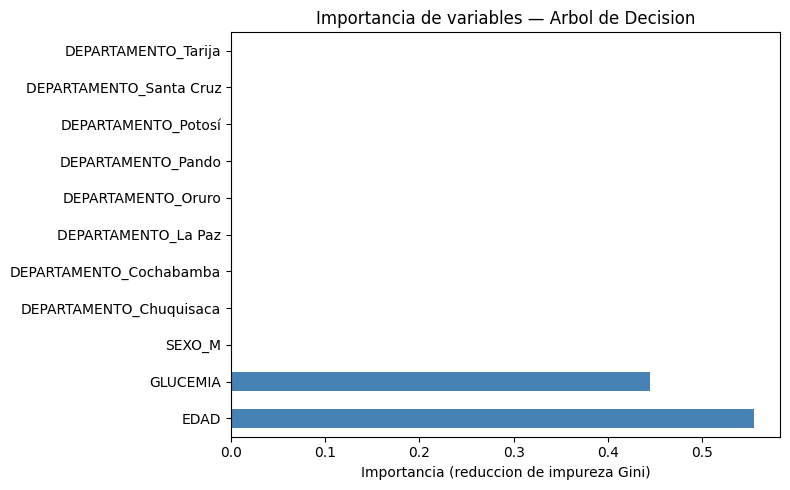

In [17]:
# Grafico 3: Importancia de variables
plt.figure(figsize=(8, 5))
importancias.plot(kind="barh", color="steelblue")
plt.title("Importancia de variables — Arbol de Decision")
plt.xlabel("Importancia (reduccion de impureza Gini)")
plt.tight_layout()
plt.show()

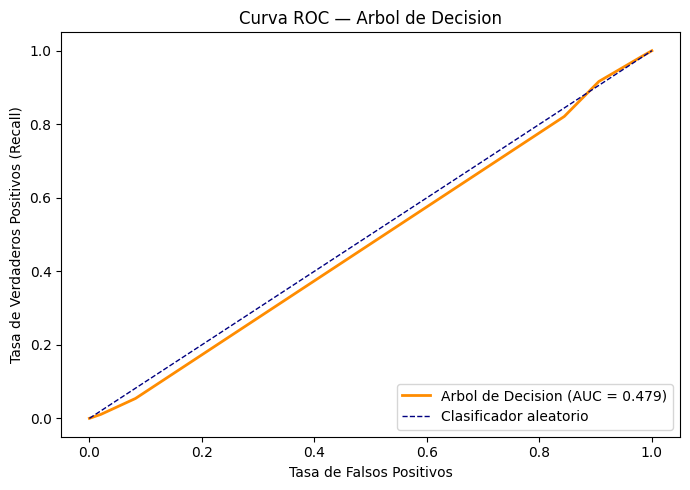

In [18]:
# Grafico 4: Curva ROC
fpr, tpr, _ = roc_curve(y_test, prob_arbol)
auc = roc_auc_score(y_test, prob_arbol)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2,
         label=f"Arbol de Decision (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Clasificador aleatorio")
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos (Recall)")
plt.title("Curva ROC — Arbol de Decision")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

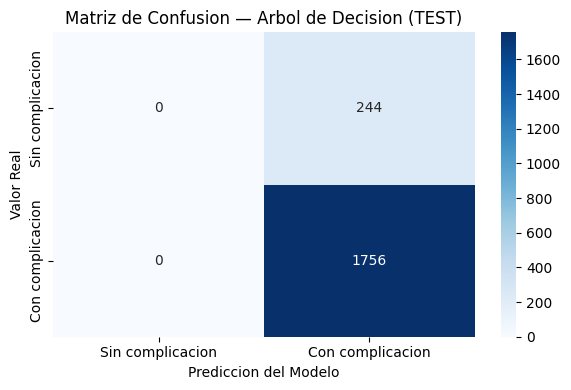

In [19]:
# Grafico 5: Matriz de confusion visual
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Sin complicacion", "Con complicacion"],
            yticklabels=["Sin complicacion", "Con complicacion"])
plt.title("Matriz de Confusion — Arbol de Decision (TEST)")
plt.ylabel("Valor Real")
plt.xlabel("Prediccion del Modelo")
plt.tight_layout()
plt.show()

R.

**Arbol de decision:** visualiza las reglas exactas que usa el modelo. La ruta mas recorrida es GLUCEMIA > 73.5 -> EDAD > 15.5 -> GLUCEMIA <= 297.5, terminando en clase Con complicacion.

**Importancia de variables:** GLUCEMIA (0.55) y EDAD (0.44) son los unicos predictores que el arbol utiliza. SEXO y DEPARTAMENTO tienen importancia 0.

**Curva ROC:** muestra la capacidad discriminante del modelo en todos los umbrales posibles. Un AUC cercano a 0.5 indica que el modelo tiene dificultades para separar las clases debido al desbalance.

**Matriz de confusion:** el modelo predice casi todos los casos como Con complicacion. Los Falsos Negativos son minimos, lo cual es favorable en contexto medico.